# 04 — Grad-CAM, uji foto sendiri, dan upload ke Hugging Face Hub

1. **Grad-CAM:** bagian daun mana yang dipakai model untuk memutuskan? Ini membuktikan model melihat bercak penyakit, bukan latar belakang.
2. **Uji foto sendiri:** seberapa bagus model pada foto HP di luar dataset? Ini bukti generalisasi paling jujur.
3. **Ekspor & upload:** model final disimpan dalam format `safetensors` lengkap dengan *model card*, lalu di-upload ke Hugging Face Hub (syarat submission).

Jalankan di **laptop (VS Code)**, cukup pakai CPU. Notebook ini memakai modul `src/model/predictor.py`, modul yang sama yang nanti dipakai aplikasi dan bot.

## 1. Konfigurasi

In [3]:
import sys, json, time, shutil
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR       = PROJECT_ROOT / "data" / "raw" / "chilli_leaf"
SPLITS_CSV     = PROJECT_ROOT / "data" / "splits.csv"
OWN_PHOTOS_DIR = PROJECT_ROOT / "data" / "own_photos"      # foto sendiri: own_photos/<nama_kelas>/*.jpg (boleh tanpa subfolder)
FINAL_CKPT     = PROJECT_ROOT / "checkpoints" / "dokter_tani_final.pt"
COMPARE_CSV    = PROJECT_ROOT / "reports" / "models" / "transfer_learning" / "perbandingan_model.csv"
OUT_DIR        = PROJECT_ROOT / "reports" / "gradcam"
EXPORT_DIR     = PROJECT_ROOT / "export" / "hf_model"

HF_REPO_ID  = "USERNAME_HF/dokter-tani-cabai"   # ganti USERNAME_HF dengan username Hugging Face Anda
PUSH_TO_HUB = False                             # ubah ke True saat siap upload
SEED = 42

OUT_DIR.mkdir(parents=True, exist_ok=True)
assert FINAL_CKPT.exists(), f"Model final belum ada: {FINAL_CKPT}. Jalankan notebook 03 dulu."
print("Model final:", FINAL_CKPT)

Model final: c:\laragon\www\final-project\dokter-tani\checkpoints\dokter_tani_final.pt


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

from src.model.predictor import DokterTaniPredictor, display_name, leaf_mask

INK, MUTED, GRID = "#18241B", "#5B6660", "#E3E6DC"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

predictor = DokterTaniPredictor(FINAL_CKPT)
ck = torch.load(FINAL_CKPT, map_location="cpu", weights_only=False)
TEST_METRICS = ck.get("test_metrics", {})
CLASSES = predictor.classes
print(f"Arsitektur: {predictor.arch} | {len(CLASSES)} kelas | input {predictor.cfg['img_size']}px")
print("Metrik test:", {k: v for k, v in TEST_METRICS.items() if k in ('test_accuracy', 'test_macro_f1', 'recall_terendah', 'cpu_ms_per_foto')})

Arsitektur: efficientnet_b0 | 6 kelas | input 224px
Metrik test: {'test_accuracy': 0.9831, 'test_macro_f1': 0.9845, 'recall_terendah': 0.974, 'cpu_ms_per_foto': 27.1}


## 2. Prediksi seluruh data test
Dipakai untuk memilih contoh Grad-CAM yang benar dan yang salah.

In [5]:
splits = pd.read_csv(SPLITS_CSV)
splits["rel_path"] = splits["rel_path"].str.replace("\\", "/", regex=False)
test = splits[splits["split"] == "test"].reset_index(drop=True)

rows = []
for rp, lab in tqdm(zip(test["rel_path"], test["label"]), total=len(test), desc="Prediksi test"):
    r = predictor.predict(DATA_DIR / rp)
    rows.append({"rel_path": rp, "label": lab, "pred": r["label"], "prob": r["prob"]})
pred = pd.DataFrame(rows)
pred["benar"] = pred["label"] == pred["pred"]
print(f"Akurasi: {pred['benar'].mean():.3f} | salah: {(~pred['benar']).sum()} dari {len(pred)} foto")

Prediksi test: 100%|██████████| 1181/1181 [01:16<00:00, 15.43it/s]

Akurasi: 0.983 | salah: 20 dari 1181 foto


## 3. Galeri Grad-CAM per kelas
Area **terang** = bagian yang paling memengaruhi keputusan model. Yang diharapkan: terang di bercak, keriting, atau lapisan putih, bukan di latar.

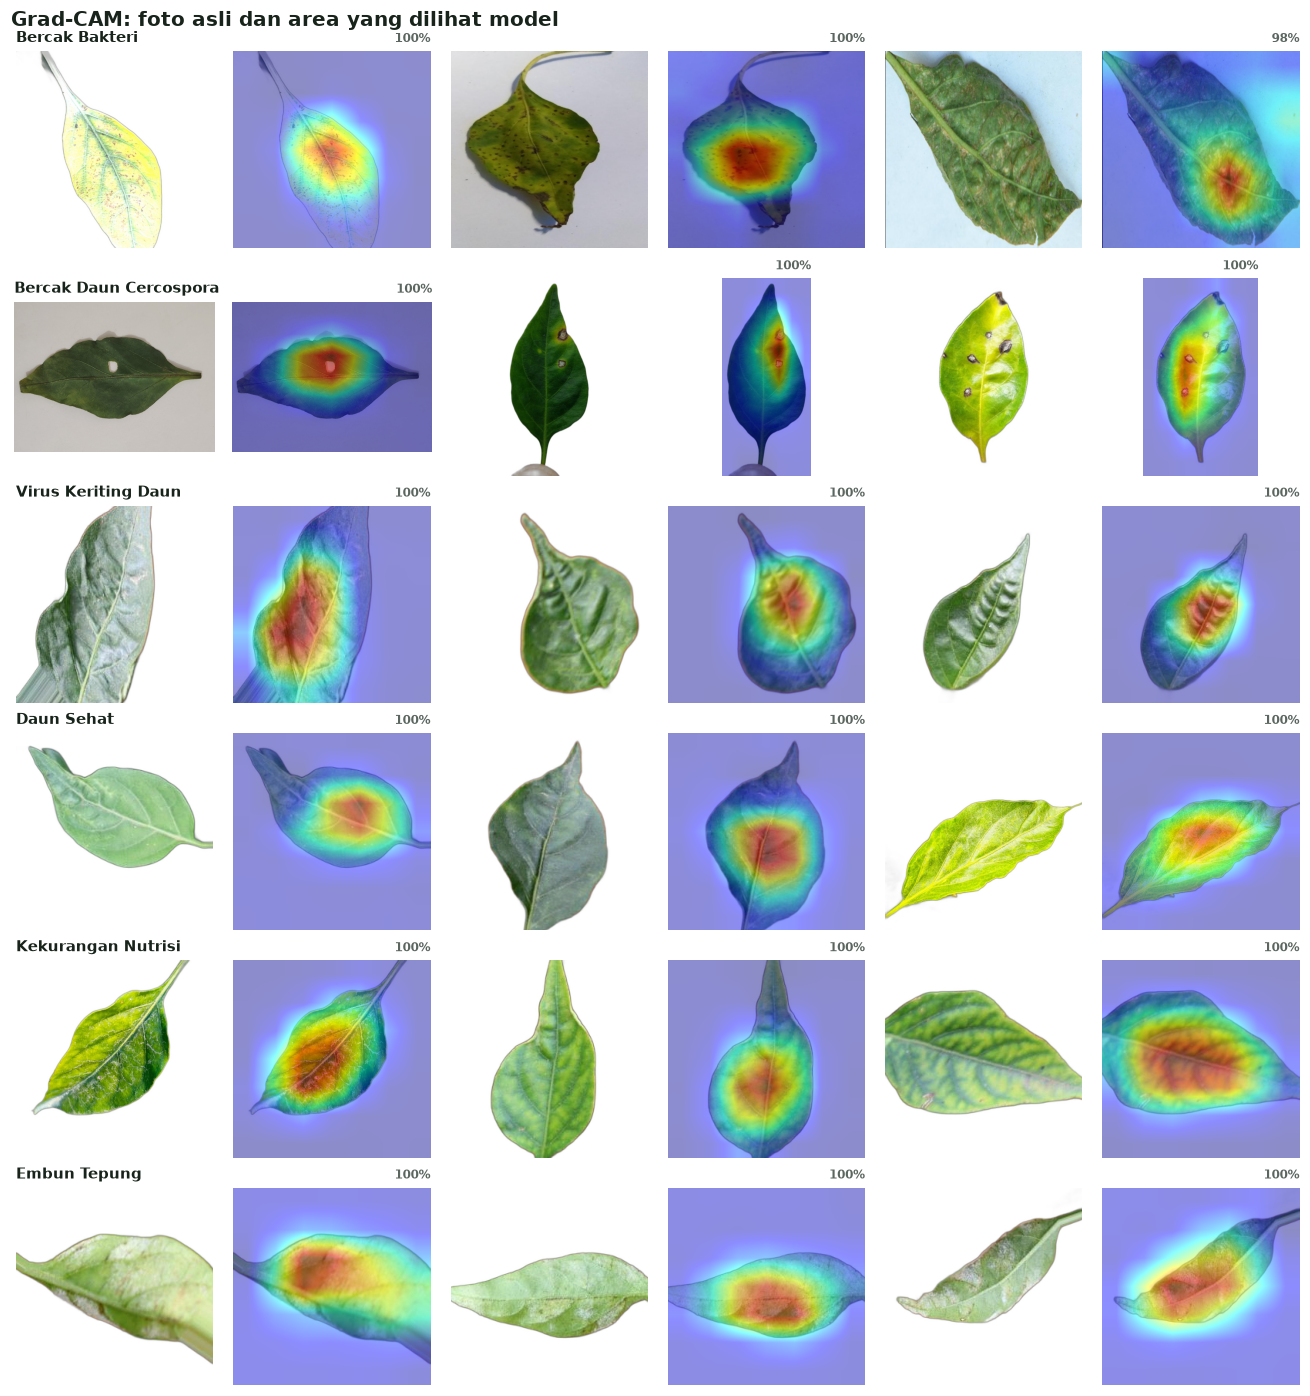

In [6]:
N = 3
fig, axes = plt.subplots(len(CLASSES), 2 * N, figsize=(2.0 * 2 * N, 2.15 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    ok_c = pred[(pred["label"] == c) & pred["benar"]]
    sample = ok_c.sample(min(N, len(ok_c)), random_state=SEED)
    for j in range(N):
        a0, a1 = axes[i, 2 * j], axes[i, 2 * j + 1]
        a0.axis("off"); a1.axis("off")
        if j < len(sample):
            img = Image.open(DATA_DIR / sample.iloc[j]["rel_path"])
            overlay, _ = predictor.gradcam(img)
            a0.imshow(ImageOps.exif_transpose(img).convert("RGB")); a1.imshow(overlay)
            a1.set_title(f"{sample.iloc[j]['prob']:.0%}", fontsize=8, color=MUTED, loc="right")
    axes[i, 0].set_title(display_name(c), loc="left", fontsize=10, fontweight="bold", color=INK)
fig.suptitle("Grad-CAM: foto asli dan area yang dilihat model", x=0.01, ha="left", fontweight="bold", color=INK, fontsize=13)
fig.tight_layout(); fig.savefig(OUT_DIR / "gradcam_per_kelas.png"); plt.show()

## 4. Grad-CAM pada salah prediksi
Kenapa model salah? Apakah fokusnya meleset, atau gejalanya memang mirip penyakit lain?

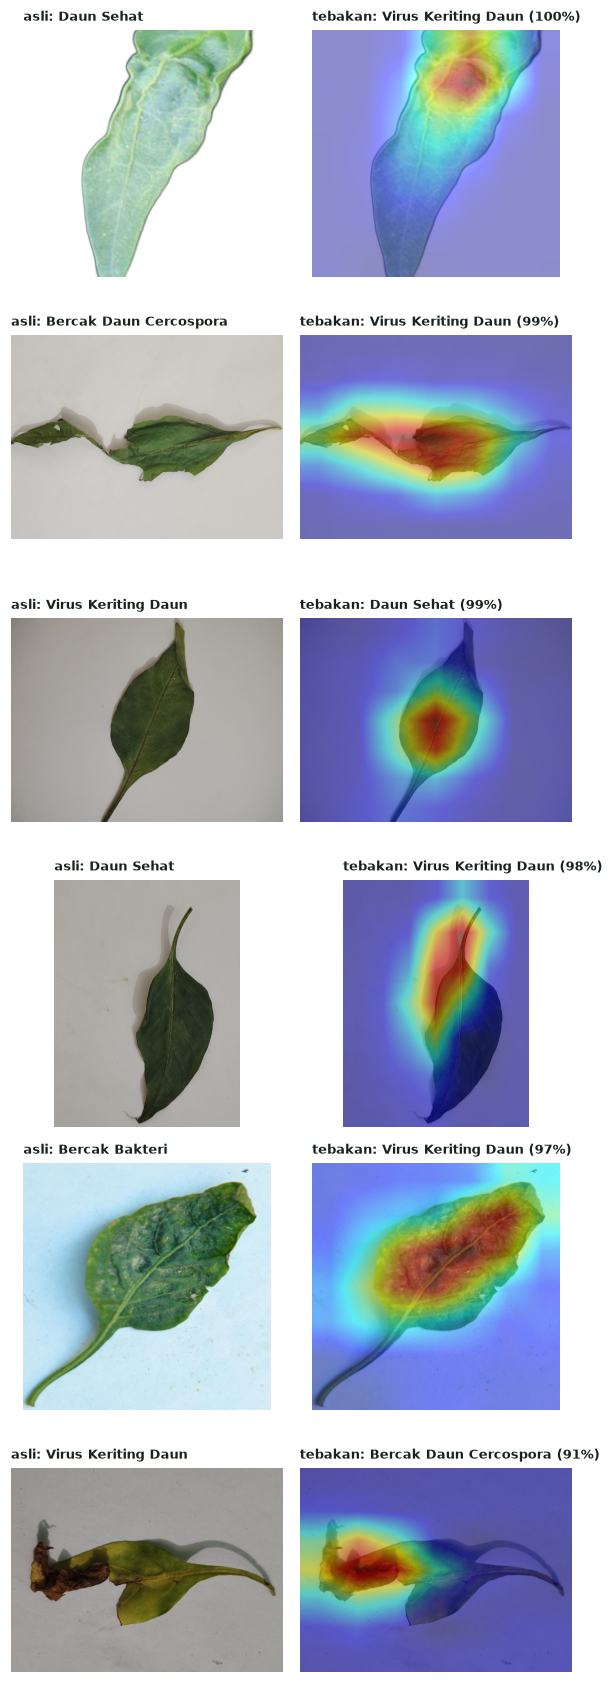

In [7]:
wrong = pred[~pred["benar"]].sort_values("prob", ascending=False).head(6)
if len(wrong):
    fig, axes = plt.subplots(len(wrong), 2, figsize=(5.4, 2.6 * len(wrong)), squeeze=False)
    for k, (_, w) in enumerate(wrong.iterrows()):
        img = Image.open(DATA_DIR / w["rel_path"])
        overlay, _ = predictor.gradcam(img)
        axes[k, 0].imshow(ImageOps.exif_transpose(img).convert("RGB")); axes[k, 1].imshow(overlay)
        axes[k, 0].set_title(f"asli: {display_name(w['label'])}", fontsize=8.5, color=INK, loc="left")
        axes[k, 1].set_title(f"tebakan: {display_name(w['pred'])} ({w['prob']:.0%})", fontsize=8.5, color=INK, loc="left")
        axes[k, 0].axis("off"); axes[k, 1].axis("off")
    fig.tight_layout(); fig.savefig(OUT_DIR / "gradcam_salah_prediksi.png"); plt.show()
else:
    print("Tidak ada salah prediksi di data test.")

## 5. Apakah model fokus ke daun?

Perkiraan kasar: berapa persen "perhatian" Grad-CAM jatuh di **area daun** (piksel berwarna) dibanding **latar** (putih atau abu-abu).
Angka tinggi = model melihat daun. Cek dulu contoh mask di bawah; kalau latar foto berwarna (tanah, rumput), angka ini kurang akurat.

In [8]:
PER_CLASS = 25
focus_rows, examples = [], []
for c in CLASSES:
    sub = pred[pred["label"] == c].sample(min(PER_CLASS, (pred["label"] == c).sum()), random_state=SEED)
    for rp in sub["rel_path"]:
        img = ImageOps.exif_transpose(Image.open(DATA_DIR / rp)).convert("RGB")
        _, cam = predictor.gradcam(img)
        mask = leaf_mask(img)
        focus_rows.append({"kelas": display_name(c), "fokus_di_daun": float((cam * mask).sum() / (cam.sum() + 1e-8)),
                           "luas_daun": float(mask.mean())})
        if len(examples) < 3 and c == CLASSES[len(examples) % len(CLASSES)]:
            examples.append((img, mask, cam))
focus = pd.DataFrame(focus_rows)
tbl = focus.groupby("kelas")[["fokus_di_daun", "luas_daun"]].mean().round(3).sort_values("fokus_di_daun")
tbl.to_csv(OUT_DIR / "fokus_di_daun.csv")
print(f"Rata-rata perhatian Grad-CAM di area daun: {focus['fokus_di_daun'].mean():.0%} "
      f"(luas daun rata-rata {focus['luas_daun'].mean():.0%} dari gambar)")
tbl

Rata-rata perhatian Grad-CAM di area daun: 61% (luas daun rata-rata 30% dari gambar)


,fokus_di_daun,luas_daun
kelas,,
Virus Keriting Daun,0.518,0.228
Embun Tepung,0.527,0.264
Bercak Bakteri,0.594,0.271
Daun Sehat,0.605,0.271
Bercak Daun Cercospora,0.689,0.388
Kekurangan Nutrisi,0.755,0.387


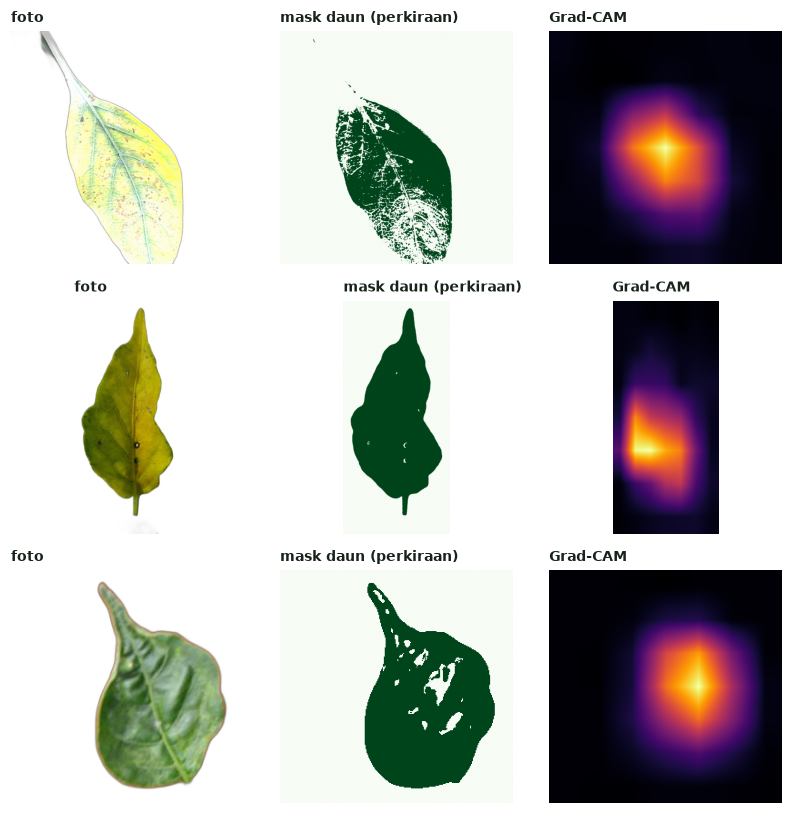

In [9]:
fig, axes = plt.subplots(len(examples), 3, figsize=(7.5, 2.5 * len(examples)), squeeze=False)
for k, (img, mask, cam) in enumerate(examples):
    axes[k, 0].imshow(img); axes[k, 1].imshow(mask, cmap="Greens"); axes[k, 2].imshow(cam, cmap="inferno")
    for a, t in zip(axes[k], ["foto", "mask daun (perkiraan)", "Grad-CAM"]):
        a.axis("off"); a.set_title(t, fontsize=9, color=INK, loc="left")
fig.tight_layout(); fig.savefig(OUT_DIR / "cek_mask_daun.png"); plt.show()

## 6. Uji dengan foto sendiri

Taruh foto HP Anda di `data/own_photos/`. Kalau dikelompokkan per subfolder dengan **nama kelas yang sama persis** dengan dataset
(misalnya `own_photos/Curl_Virus/foto1.jpg`), akurasinya ikut dihitung. Tanpa subfolder, hanya prediksinya yang ditampilkan.

In [10]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp"}
own = sorted(p for p in OWN_PHOTOS_DIR.rglob("*") if p.suffix.lower() in IMG_EXT) if OWN_PHOTOS_DIR.exists() else []
own_df = None
if not own:
    print(f"Belum ada foto di {OWN_PHOTOS_DIR}. Tambahkan foto, lalu jalankan ulang sel ini.")
else:
    recs = []
    for p in own:
        r = predictor.predict(p)
        true = p.parent.name if p.parent != OWN_PHOTOS_DIR and p.parent.name in CLASSES else None
        recs.append({"file": p.relative_to(OWN_PHOTOS_DIR).as_posix(), "label": true, "pred": r["label"],
                     "nama": r["nama"], "prob": round(r["prob"], 3)})
    own_df = pd.DataFrame(recs)
    own_df.to_csv(OUT_DIR / "prediksi_foto_sendiri.csv", index=False)
    labeled = own_df.dropna(subset=["label"])
    if len(labeled):
        print(f"Foto berlabel: {len(labeled)} | akurasi {accuracy_score(labeled['label'], labeled['pred']):.3f} | "
              f"macro F1 {f1_score(labeled['label'], labeled['pred'], average='macro'):.3f}")
    print(f"Keyakinan < 60% (bot akan minta foto ulang): {(own_df['prob'] < 0.6).sum()} dari {len(own_df)} foto")

    n = min(8, len(own))
    fig, axes = plt.subplots(2, n, figsize=(2.3 * n, 5), squeeze=False)
    for k in range(n):
        img = Image.open(own[k]); overlay, _ = predictor.gradcam(img)
        axes[0, k].imshow(ImageOps.exif_transpose(img).convert("RGB")); axes[1, k].imshow(overlay)
        row = own_df.iloc[k]
        axes[0, k].set_title(f"{row['nama']}\n{row['prob']:.0%}", fontsize=8, color=INK, loc="left")
        axes[0, k].axis("off"); axes[1, k].axis("off")
    fig.tight_layout(); fig.savefig(OUT_DIR / "foto_sendiri.png"); plt.show()
    display(own_df)

Belum ada foto di c:\laragon\www\final-project\dokter-tani\data\own_photos. Tambahkan foto, lalu jalankan ulang sel ini.


## 7. Ekspor model untuk Hugging Face

Folder `export/hf_model/` berisi:
- `model.safetensors`: bobot model (format aman dan standar Hugging Face)
- `config.json`: arsitektur, nama kelas, ukuran input, normalisasi
- `predictor.py`: kode untuk memakai model
- `README.md`: *model card* (deskripsi, metrik, keterbatasan)

In [11]:
from safetensors.torch import save_file

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)
EXPORT_DIR.mkdir(parents=True)

save_file({k: v.contiguous() for k, v in ck["model"].items()}, str(EXPORT_DIR / "model.safetensors"))
config = {"arch": predictor.arch, "classes": CLASSES, "display_names": {c: display_name(c) for c in CLASSES},
          "img_size": predictor.cfg["img_size"], "mean": predictor.cfg["mean"], "std": predictor.cfg["std"],
          "test_metrics": {k: v for k, v in TEST_METRICS.items() if not str(k).startswith("_")}}
(EXPORT_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
shutil.copy(PROJECT_ROOT / "src" / "model" / "predictor.py", EXPORT_DIR / "predictor.py")

# Contoh Grad-CAM untuk ditampilkan di model card
if (OUT_DIR / "gradcam_per_kelas.png").exists():
    shutil.copy(OUT_DIR / "gradcam_per_kelas.png", EXPORT_DIR / "gradcam_per_kelas.png")

# Pastikan hasil ekspor memberi prediksi yang sama dengan checkpoint asli
check = DokterTaniPredictor(EXPORT_DIR)
sample_path = DATA_DIR / test["rel_path"].iloc[0]
assert check.predict(sample_path)["label"] == predictor.predict(sample_path)["label"]
print("Ekspor OK:", sorted(p.name for p in EXPORT_DIR.iterdir()))

Ekspor OK: ['config.json', 'gradcam_per_kelas.png', 'model.safetensors', 'predictor.py']


In [12]:
m = TEST_METRICS
compare_md = ""
if COMPARE_CSV.exists():
    cmp = pd.read_csv(COMPARE_CSV)
    keep = [c for c in ["model", "params_jt", "test_accuracy", "test_macro_f1", "recall_terendah", "cpu_ms_per_foto"] if c in cmp]
    cmp = cmp[keep].fillna("–")
    compare_md = ("\n## Perbandingan model\n\n| " + " | ".join(keep) + " |\n|" + "---|" * len(keep) + "\n"
                  + "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in cmp.values) + "\n")

class_lines = "\n".join(f"| `{c}` | {display_name(c)} |" for c in CLASSES)
gradcam_md = "\n## Grad-CAM\n\n![Grad-CAM per kelas](gradcam_per_kelas.png)\n" if (EXPORT_DIR / "gradcam_per_kelas.png").exists() else ""

card = f'''---
license: other
library_name: pytorch
pipeline_tag: image-classification
tags:
  - image-classification
  - agriculture
  - plant-disease
  - chili
  - pytorch
---

# Dokter Tani — Klasifikasi Penyakit Daun Cabai

Model {predictor.arch} (transfer learning dari ImageNet) untuk mengenali **{len(CLASSES)} kondisi daun cabai** dari foto.
Dibuat sebagai final project AI Engineering Bootcamp, dipakai oleh bot Telegram *Dokter Tani* untuk membantu petani cabai.

## Kelas

| Label | Nama |
|---|---|
{class_lines}

## Hasil di data test

| Metrik | Nilai |
|---|---|
| Accuracy | {m.get("test_accuracy", "–")} |
| Macro F1 | {m.get("test_macro_f1", "–")} |
| Recall kelas terendah | {m.get("recall_terendah", "–")} |
| Waktu inferensi CPU | {m.get("cpu_ms_per_foto", "–")} ms/foto |
{compare_md}{gradcam_md}
## Data

- [Chilli Leaf Disease Image Dataset (Mendeley Data)](https://data.mendeley.com/datasets/tm3v4zmh7c/1), foto lapangan dari Bangladesh.
- Dibersihkan dari file kembar; pembagian train/val/test 70/15/15 dikelompokkan per foto yang mirip agar tidak bocor.

## Cara pakai

Unduh `predictor.py` dari repo ini (butuh `torch`, `torchvision`, `safetensors`, `huggingface_hub`), lalu:

```python
from predictor import DokterTaniPredictor
p = DokterTaniPredictor.from_hub("{HF_REPO_ID}")
hasil = p.predict("daun.jpg")              # label, nama, prob, top-3
overlay, cam = p.gradcam("daun.jpg")       # visualisasi Grad-CAM
```

## Keterbatasan

- Dilatih pada foto dari satu sumber dataset; akurasi pada foto HP di kondisi lapangan lain bisa lebih rendah.
- Hanya mengenali {len(CLASSES)} kondisi di atas; penyakit lain akan tetap ditebak sebagai salah satunya.
- Hasil adalah **bantuan awal**, bukan pengganti penyuluh pertanian. Untuk serangan berat atau dosis obat, konsultasikan ke penyuluh.
'''
(EXPORT_DIR / "README.md").write_text(card, encoding="utf-8")
print(card[:1500])

---
license: other
library_name: pytorch
pipeline_tag: image-classification
tags:
  - image-classification
  - agriculture
  - plant-disease
  - chili
  - pytorch
---

# Dokter Tani — Klasifikasi Penyakit Daun Cabai

Model efficientnet_b0 (transfer learning dari ImageNet) untuk mengenali **6 kondisi daun cabai** dari foto.
Dibuat sebagai final project AI Engineering Bootcamp, dipakai oleh bot Telegram *Dokter Tani* untuk membantu petani cabai.

## Kelas

| Label | Nama |
|---|---|
| `Bacterial_Spot` | Bercak Bakteri |
| `Cercospora_Leaf_Spot` | Bercak Daun Cercospora |
| `Curl_Virus` | Virus Keriting Daun |
| `Healthy_Leaf` | Daun Sehat |
| `Nutrition_Deficiency` | Kekurangan Nutrisi |
| `Powdery_Mildew` | Embun Tepung |

## Hasil di data test

| Metrik | Nilai |
|---|---|
| Accuracy | 0.9831 |
| Macro F1 | 0.9845 |
| Recall kelas terendah | 0.974 |
| Waktu inferensi CPU | 27.1 ms/foto |

## Perbandingan model

| model | params_jt | test_accuracy | test_macro_f1 | recall_terendah | cpu

## 8. Upload ke Hugging Face Hub

1. Buat token di **huggingface.co → Settings → Access Tokens → Create new token** (tipe *Write*).
2. Ganti `HF_REPO_ID` di sel Konfigurasi, set `PUSH_TO_HUB = True`, lalu jalankan sel ini. Token akan diminta (tidak disimpan di notebook).

In [13]:
if not PUSH_TO_HUB:
    print("PUSH_TO_HUB = False → upload dilewati. Folder siap di:", EXPORT_DIR)
else:
    import os, getpass
    from huggingface_hub import HfApi
    assert "USERNAME_HF" not in HF_REPO_ID, "Ganti USERNAME_HF di HF_REPO_ID dengan username Hugging Face Anda."
    token = os.environ.get("HF_TOKEN") or getpass.getpass("Token Hugging Face (Write): ")
    api = HfApi(token=token)
    api.create_repo(HF_REPO_ID, repo_type="model", exist_ok=True)
    api.upload_folder(folder_path=str(EXPORT_DIR), repo_id=HF_REPO_ID, repo_type="model",
                      commit_message="Upload model Dokter Tani")
    print(f"Berhasil: https://huggingface.co/{HF_REPO_ID}")

    # Uji: unduh ulang dari Hub dan prediksi
    hub = DokterTaniPredictor.from_hub(HF_REPO_ID, token=token)
    print("Uji dari Hub:", hub.predict(sample_path)["nama"])

PUSH_TO_HUB = False → upload dilewati. Folder siap di: c:\laragon\www\final-project\dokter-tani\export\hf_model


## 9. Ringkasan untuk `CATATAN.md`

In [14]:
today = time.strftime("%Y-%m-%d")
own_txt = "belum ada foto sendiri"
if own_df is not None:
    lab = own_df.dropna(subset=["label"])
    own_txt = (f"{len(own_df)} foto sendiri, akurasi {accuracy_score(lab['label'], lab['pred']):.2f}" if len(lab)
               else f"{len(own_df)} foto sendiri (tanpa label)")
print(f"| {today} | Grad-CAM + uji foto sendiri ({predictor.arch}) | perhatian di area daun ±{focus['fokus_di_daun'].mean():.0%}; "
      f"{own_txt} | {'Model di-upload ke ' + HF_REPO_ID if PUSH_TO_HUB else 'Ekspor siap upload ke Hugging Face'} |")

| 2026-10-18 | Grad-CAM + uji foto sendiri (efficientnet_b0) | perhatian di area daun ±61%; belum ada foto sendiri | Ekspor siap upload ke Hugging Face |


### Bahan slide dari notebook ini
- `gradcam_per_kelas.png`: bukti model melihat gejala penyakit (slide metodologi / explainability)
- `gradcam_salah_prediksi.png`: bahan diskusi *Challenges*
- `foto_sendiri.png`: bukti uji di dunia nyata (slide *Impact*)

**Berikutnya:** RAG + agent (dokumen panduan penyakit cabai), lalu aplikasi Gradio dan bot Telegram.